<a href="https://colab.research.google.com/github/kingajutrzenka/World-happiness-report-2024/blob/main/Szcz%C4%99%C5%9Bcie.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Raport o szczęściu na świecie 2024**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

‼ Uwaga, dane z usuniętymi brakami to d3

In [2]:
dane = pd.read_csv("World-happiness-report-2024.csv")
dane.head()

,Country name,Regional indicator,Ladder score,upperwhisker,lowerwhisker,Log GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption,Dystopia + residual
0,Finland,Western Europe,7.741,7.815,7.667,1.844,1.572,0.695,0.859,0.142,0.546,2.082
1,Denmark,Western Europe,7.583,7.665,7.500,1.908,1.520,0.699,0.823,0.204,0.548,1.881
2,Iceland,Western Europe,7.525,7.618,7.433,1.881,1.617,0.718,0.819,0.258,0.182,2.050
3,Sweden,Western Europe,7.344,7.422,7.267,1.878,1.501,0.724,0.838,0.221,0.524,1.658
4,Israel,Middle East and North Africa,7.341,7.405,7.277,1.803,1.513,0.740,0.641,0.153,0.193,2.298


## **Podstawowe informacje o zbiorze danych**

**Wymiary zbioru**

In [14]:
dane.shape

(143, 12)

Zbiór ma 143 wiersze i 12 kolumn

**Braki danych**

In [11]:
dane.isnull().sum()


,0
Country name,0
Regional indicator,0
Ladder score,0
upperwhisker,0
lowerwhisker,0
Log GDP per capita,3
Social support,3
Healthy life expectancy,3
Freedom to make life choices,3
Generosity,3


W zbiorze występują po 3 braki danych w kolumnach: "Log GDP per capita", "Social support", "Healthy life expectancy", "Freedom to make life choices", "Generosity", "Perceptions of corruption" oraz "Dystopia + residual". Poza kolumną "Dystopia + residual" są to dane służące do badania ich wpływu na "Ladder score" (poziom szczęscia). Z tego względu sprawdzimy, gdzie te braki występują.

In [13]:
dane[dane.isnull().any(axis=1)]

#wyświetla wiersze, gdzie jest przynajmniej jeden brak danych

,Country name,Regional indicator,Ladder score,upperwhisker,lowerwhisker,Log GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption,Dystopia + residual
61,Bahrain,Middle East and North Africa,5.959,6.153,5.766,NaN,NaN,NaN,NaN,NaN,NaN,NaN
87,Tajikistan,Commonwealth of Independent States,5.281,5.361,5.201,NaN,NaN,NaN,NaN,NaN,NaN,NaN
102,State of Palestine,Middle East and North Africa,4.879,5.006,4.753,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Braki danych występują dla 3 kraji. W przypadku każdego kraju znamy poziom szczęścia, ale nie mamy danych które służą do badania wpływu czynników na poziom szczęścia. Jako, że celem tego projektu jest zbadania zależności między m.in. poziomem PKB per capita, a poziomem szczęścia, to nie użyjemy tych trzech krajów w dalszej analizie, ponieważ nie wnoszą one informacji do dalszego badania.

In [21]:
d3 = dane.dropna()

In [18]:
d3.shape

(140, 12)

**Typy danych**

In [20]:
d3.dtypes

,0
Country name,object
Regional indicator,object
Ladder score,float64
upperwhisker,float64
lowerwhisker,float64
Log GDP per capita,float64
Social support,float64
Healthy life expectancy,float64
Freedom to make life choices,float64
Generosity,float64


W zbiorze mamy 2 kolumny z typem object - dane tekstowe: "Country name" oraz "Regional indicator". Reszta kolumn ma typ float64, czyli są to liczby zmiennoprzecinkowe.:

## **Badanie zależności**

Do badania wpływu czynników na poziom szczęścia nie przydadzą nam się kolumny : "Country name", "Regional indicator", "upperwhisker", "lowerwhisker" oraz "Dystopia + residual", dlatego też usunę je przed przejściem do badania korelacji

In [27]:
dk = d3.drop(columns=["Country name", "Regional indicator", "upperwhisker", "lowerwhisker", "Dystopia + residual"])

Text(0.5, 1.0, 'Macierz korelacji czynników wpływu na poziom szczęścia')

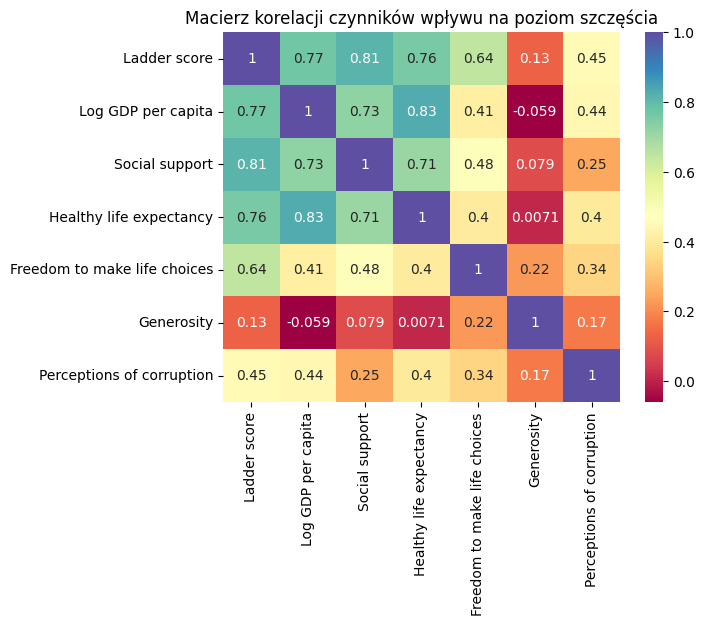

In [31]:
corr = dk.corr(numeric_only=True)
sns.heatmap(corr, cmap="Spectral", annot=True)
plt.title("Macierz korelacji czynników wpływu na poziom szczęścia")